# The lithography toolbox: sources, masks, mask and wafer stacks, process windows

`pyoptics.litho` splits a lithographic imaging simulation into exchangeable
parts. Notebook 31 used it for the polarization physics of hyper-NA
immersion imaging; this notebook walks through all parts:

| Part | Classes / functions | Options |
|---|---|---|
| illumination | `Illumination.coherent/conventional/annular/dipole/quadrupole/quasar/multipole/dipole_for_pitch/from_map` | any sigma, sector or circular poles, rotation; polarization `"x"`, `"y"`, `"TE"` (azimuthal), `"TM"` (radial), `"unpolarized"`, Jones or Stokes vectors, callables, degree of polarization `dop` |
| mask layout | `MaskLayout.lines_spaces/iso_line/contact_holes/iso_contact/staggered_contacts`, or any rectangles | clear or dark field (`tone`), 1D or 2D, analytic diffraction orders |
| mask stack | `ThinMask.binary/att_psm`, `FilmMask(n, k, t)`, `BoundaryLayer(w, t_TE, t_TM)` | Kirchhoff thin mask; absorber transmissions from `thin_films` (angle and TE/TM dependent); boundary layer model for thick mask edges |
| projector | `Projector(NA, wavelength, n, magnification, vectorial, obliquity, zernikes, phase, apodization_zernikes, apodization, apodization_model)` | immersion or dry, scalar or vectorial, Fringe Zernike aberrations, apodization (amplitude 1 + Σ Fringe Zernikes, or their log amplitude, or any function) |
| wafer | `WaferStack(resist, below, substrate, above)` | aerial image (None) or image in the resist with BARC, top coat, substrate (TE/TM Fresnel transmission, standing waves) |
| simulation | `LithoSimulation(...)`: `image`, `cut`, `through_focus`, `cd`, `dose_to_size`, `nils`, `meef`, `fem`, `open_frame` | Abbe's method, exact sum over orders on any grid, images normalized to the open frame |
| metrics | `litho.metrics`: `contrast`, `nils`, `image_log_slope`, `threshold_cd`, `feature_edges`, `nils_at_threshold`, `dose_to_size`, `fem_cd`, `process_window`, `el_dof`, `dof_at_el`, `gaussian_blur` | threshold resist model |
| plots | `litho.plot`: `plot_source`, `plot_mask`, `plot_pupil_fill`, `plot_image`, `plot_bossung`, `plot_process_window` | |

A simulation in four lines:

```python
sim = LithoSimulation(MaskLayout.contact_holes(110, 55), ThinMask.att_psm(0.06),
                      Illumination.quasar(0.95, 0.7, polarization="TE"),
                      Projector(1.35, 193, n=1.437))
I = sim.image(x, y)
```

All lengths are image-side (wafer scale) values in nm, mask dimensions
included (1x). Most of the notebook uses ArF immersion (193 nm, water,
NA 1.35); section 10 repeats the main steps for KrF (248 nm, dry). The
material data of both wavelengths are collected in `MATERIALS` below; they
are approximate values for illustration (the optical constants of real
resists, BARCs and absorbers vary between products), so replace them with
measured data for quantitative work. Convention:
$\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import (Illumination, MaskLayout, ThinMask, FilmMask, BoundaryLayer, Projector,
                            WaferStack, LithoSimulation, metrics)
from pyoptics.litho.plot import (plot_source, plot_mask, plot_pupil_fill, plot_image, plot_bossung,
                                 plot_process_window)

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

# approximate optical constants (n, k) at the ArF and KrF wavelengths
MATERIALS = {
    "ArF": {"wavelength": 193.0, "water": (1.437, 0.0), "fused silica": (1.563, 0.0),
            "MoSi": (2.343, 0.586), "Cr": (0.84, 1.65), "resist": (1.70, 0.03),
            "BARC": (1.82, 0.34), "Si": (0.883, 2.778)},
    "KrF": {"wavelength": 248.0, "water": None, "fused silica": (1.508, 0.0),
            "MoSi": (2.18, 0.48), "Cr": (1.9, 1.9), "resist": (1.76, 0.01),
            "BARC": (1.50, 0.45), "Si": (1.57, 3.565)},
}


def film_mask(absorber, thickness, line="ArF", **kwargs):
    """Single layer absorber of MATERIALS[line] on the fused silica blank."""

    m = MATERIALS[line]
    n, k = m[absorber]
    kwargs.setdefault("name", f"{absorber} {thickness:.1f} nm")
    return FilmMask([n], [k], [thickness], substrate_n=m["fused silica"][0], **kwargs)


def layer(material, thickness, line="ArF"):
    """(n, k, thickness) of a material of MATERIALS[line]."""

    return MATERIALS[line][material] + (thickness,)


wl, n_w, NA = 193.0, 1.437, 1.35
water = Projector(NA, wl, n_w)

## 1. Illumination

Sources are sampled on a square grid in the sigma plane (`n_samples` points
across the unit circle); every point is a plane wave, mutually incoherent
with all others. Top row: shapes (any inner and outer sigma, sector or
circular poles, rotated quadrupoles, a freeform map). Bottom row:
polarizations on an annular source; the ticks show the Jones vector of
each point, partially polarized light (`dop`) is a mix of the state with
unpolarized light.

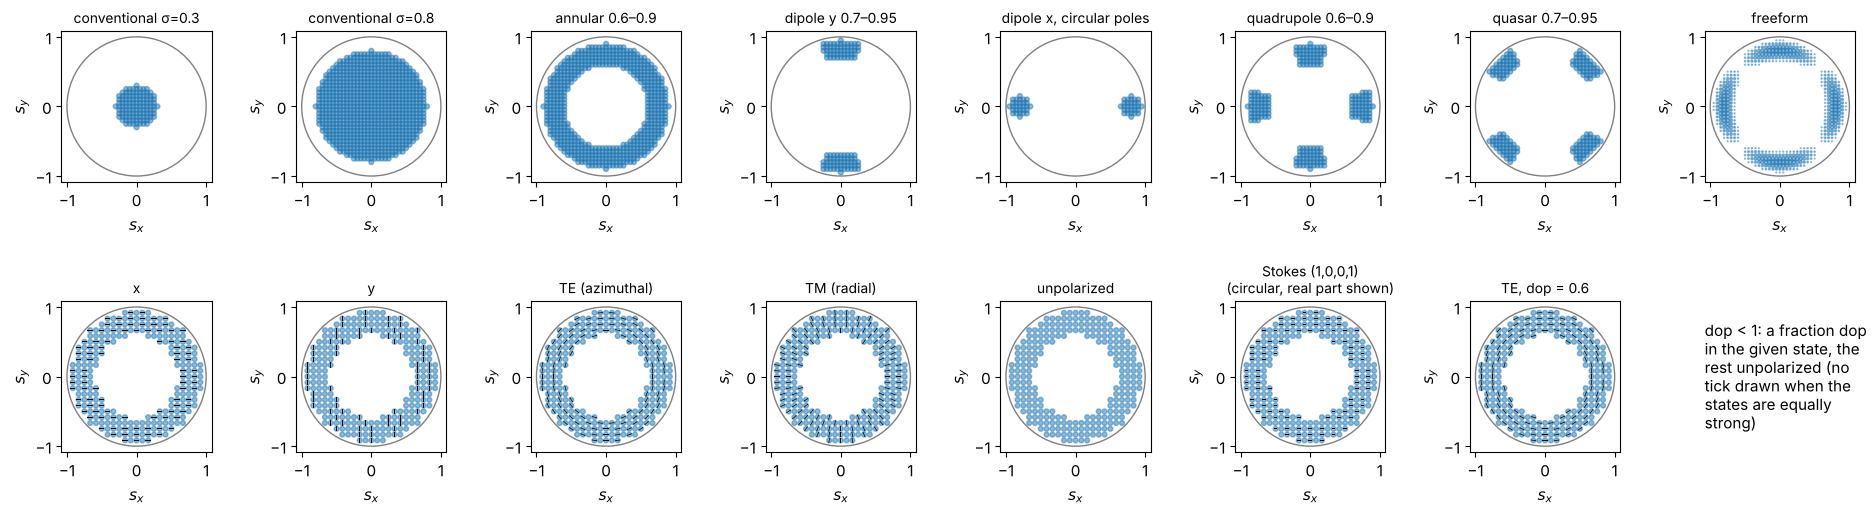

In [2]:
S_x, S_y = np.meshgrid(np.linspace(-1, 1, 41), np.linspace(-1, 1, 41))
freeform = np.exp(-((np.hypot(S_x, S_y) - 0.8)/0.08)**2)*(1 + np.cos(4*np.arctan2(S_y, S_x)))
shapes = [Illumination.conventional(0.3, n_samples=41),
          Illumination.conventional(0.8, n_samples=41),
          Illumination.annular(0.9, 0.6, n_samples=41),
          Illumination.dipole(0.95, 0.7, 35, axis="y", n_samples=41),
          Illumination.dipole(0.95, 0.65, axis="x", pole="circle", n_samples=41, name="dipole x, circular poles"),
          Illumination.quadrupole(0.9, 0.6, 30, n_samples=41),
          Illumination.quasar(0.95, 0.7, 30, n_samples=41),
          Illumination.from_map(S_x, S_y, freeform, threshold=0.05)]
annular = Illumination.annular(0.95, 0.6, n_samples=25)
pols = [("x", 1.0), ("y", 1.0), ("TE", 1.0), ("TM", 1.0), ("unpolarized", 1.0),
        (np.array([1.0, 0.0, 0.0, 1.0]), 1.0), ("TE", 0.6)]
pol_names = ["x", "y", "TE (azimuthal)", "TM (radial)", "unpolarized", "Stokes (1,0,0,1)\n(circular, real part shown)",
             "TE, dop = 0.6"]
fig, axes = plt.subplots(2, 8, figsize=(19, 5.4))
for ax, ill in zip(axes[0], shapes):
    plot_source(ill, ax=ax, show_polarization=False)
for ax, (pol, dop), name in zip(axes[1], pols, pol_names):
    plot_source(annular.with_polarization(pol, dop), ax=ax, every=2, title=name)
axes[1, -1].axis("off")
axes[1, -1].text(0, 0.5, "dop < 1: a fraction dop\nin the given state, the\nrest unpolarized (no\ntick drawn when the\nstates are equally\nstrong)", va="center")
fig.tight_layout()

Which source suits which pattern? NILS of 45 nm lines and spaces (vertical
lines, pitch 90 nm) and of 65 nm contact holes at 130 nm pitch (dark
field), binary masks, all TE/azimuthally polarized except the
dipoles (y polarized = TE for vertical lines). The dipole is best for
one line direction but useless for the other one; for the holes, which
need both directions, the quasar is the best of these sources (the
conventional source with σ = 0.5 cannot resolve the 90 nm pitch at all).

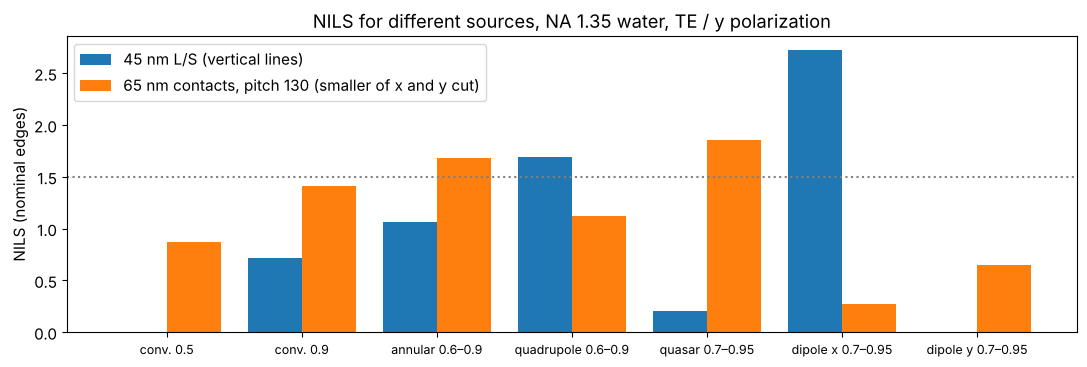

In [3]:
src_cmp = {"conv. 0.5": Illumination.conventional(0.5), "conv. 0.9": Illumination.conventional(0.9),
           "annular 0.6–0.9": Illumination.annular(0.9, 0.6), "quadrupole 0.6–0.9": Illumination.quadrupole(0.9, 0.6),
           "quasar 0.7–0.95": Illumination.quasar(0.95, 0.7), "dipole x 0.7–0.95": Illumination.dipole(0.95, 0.7),
           "dipole y 0.7–0.95": Illumination.dipole(0.95, 0.7, axis="y")}
ls45 = MaskLayout.lines_spaces(90.0, 45.0)
ch65 = MaskLayout.contact_holes(130.0, 65.0)
rows = []
for name, ill in src_cmp.items():
    pol = "y" if "dipole" in name else "TE"
    ill = ill.with_polarization(pol)
    n_ls = LithoSimulation(ls45, ThinMask.binary(), ill, water).nils()
    s_ch = LithoSimulation(ch65, ThinMask.binary(), ill, water)
    n_ch = min(s_ch.nils(direction="x"), s_ch.nils(direction="y"))
    rows.append((name, n_ls, n_ch))
fig, ax = plt.subplots(figsize=(11, 3.8))
idx = np.arange(len(rows))
ax.bar(idx - 0.2, [r[1] for r in rows], 0.4, label="45 nm L/S (vertical lines)")
ax.bar(idx + 0.2, [r[2] for r in rows], 0.4, label="65 nm contacts, pitch 130 (smaller of x and y cut)")
ax.set_xticks(idx); ax.set_xticklabels([r[0] for r in rows], fontsize=9)
ax.axhline(1.5, color="gray", ls=":"); ax.set_ylabel("NILS (nominal edges)"); ax.legend()
ax.set_title("NILS for different sources, NA 1.35 water, TE / y polarization")
fig.tight_layout()

## 2. Mask layouts

A `MaskLayout` is one period with rectangular features; the diffraction
orders are products of sinc functions (no pixelation). The pupil fill shows
where the orders land in the pupil for all source points: only what lands
inside contributes. Below: lines and spaces, an isolated line (pitch 20 cd),
a trench (dark field line), dense and isolated contact holes and a
staggered contact array, imaged with suitable sources.

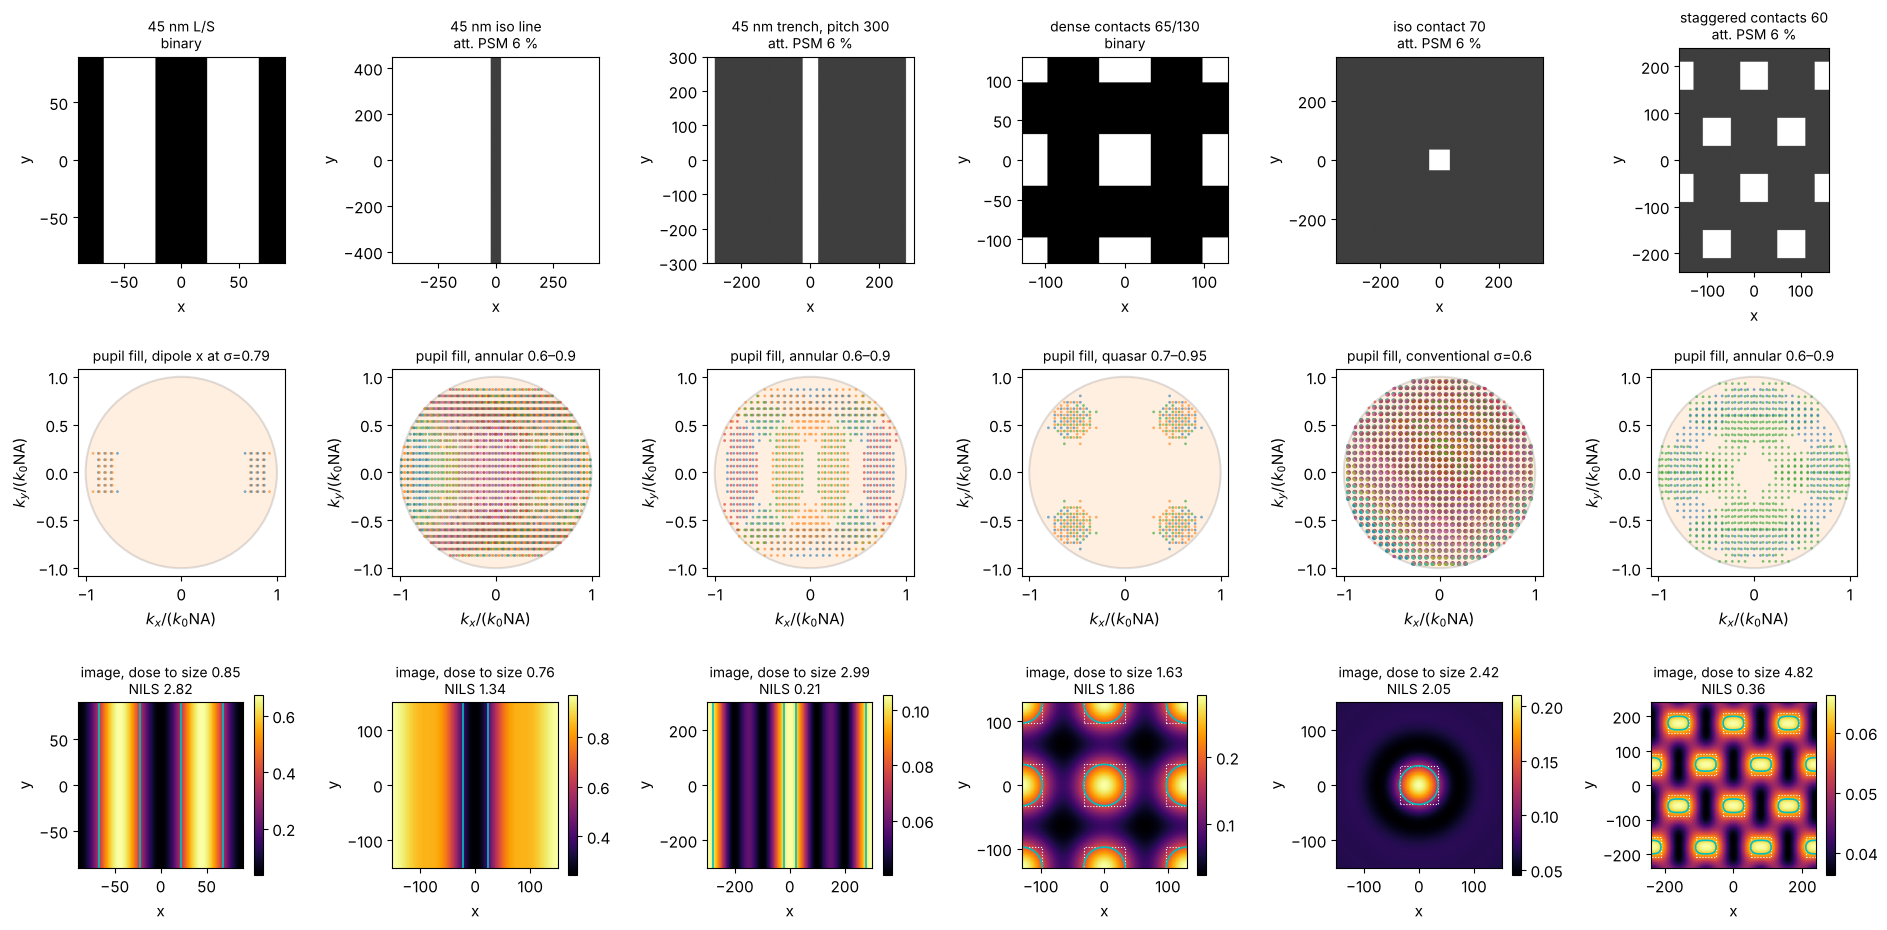

In [4]:
cases = [("45 nm L/S", MaskLayout.lines_spaces(90.0, 45.0), ThinMask.binary(), Illumination.dipole_for_pitch(90.0, wl, NA, polarization="y")),
         ("45 nm iso line", MaskLayout.iso_line(45.0, pitch=900.0), ThinMask.att_psm(0.06), Illumination.annular(0.9, 0.6, polarization="TE")),
         ("45 nm trench, pitch 300", MaskLayout.lines_spaces(300.0, 45.0, tone="dark"), ThinMask.att_psm(0.06), Illumination.annular(0.9, 0.6, polarization="TE")),
         ("dense contacts 65/130", MaskLayout.contact_holes(130.0, 65.0), ThinMask.binary(), Illumination.quasar(0.95, 0.7, polarization="TE")),
         ("iso contact 70", MaskLayout.iso_contact(70.0, pitch=700.0), ThinMask.att_psm(0.06), Illumination.conventional(0.6, polarization="TE")),
         ("staggered contacts 60", MaskLayout.staggered_contacts(160.0, 120.0, 60.0), ThinMask.att_psm(0.06), Illumination.annular(0.9, 0.6, polarization="TE"))]
fig, axes = plt.subplots(3, len(cases), figsize=(19, 9.5))
for j, (name, layout, stack, ill) in enumerate(cases):
    sim = LithoSimulation(layout, stack, ill, water)
    plot_mask(layout, ax=axes[0, j], periods=1 if "iso" in name else 2, t_absorber=abs(stack.t_absorber),
              title=f"{name}\n{stack.name}")
    plot_pupil_fill(sim, ax=axes[1, j], title=f"pupil fill, {ill.name}")
    L = 300.0 if "iso" in name else 2*max(layout.pitch_x or 0, layout.pitch_y or 0)
    x = np.linspace(-L/2, L/2, 121)
    D = sim.dose_to_size(threshold=0.3)
    plot_image(sim, x, sim.image(x, x), x, ax=axes[2, j], threshold=0.3, dose=D)
    axes[2, j].set_title(f"image, dose to size {D:.2f}\nNILS {sim.nils():.2f}", fontsize=10)
fig.tight_layout()

(Cyan: printed contour of the threshold resist at the dose to size,
dotted: the mask features. Images are normalized to the open frame, so
the dose to size of a dark field mask is large.)

## 3. Dense and isolated: through pitch

The same feature prints differently in dense and isolated surroundings
(iso-dense bias, optical proximity effect). At the dose that sizes the
densest pitch, the CD changes through pitch: here the 60 nm lines (att.
PSM, annular) shrink by about 20 nm at intermediate pitches, where the
off-axis source, tuned to the dense pitch, images poorly; the 65 nm holes
(binary, conventional) change much less. (Holes on a dark field att. PSM
sized at the dense pitch do not open at all at larger pitches: the dense
holes profit from the light of their neighbours.)
Optical proximity correction (OPC) biases the mask features to compensate;
the MEEF (mask error enhancement factor, $\partial\mathrm{CD_{wafer}}/\partial\mathrm{CD_{mask}}$ at wafer
scale) tells how strongly mask CD errors are amplified.

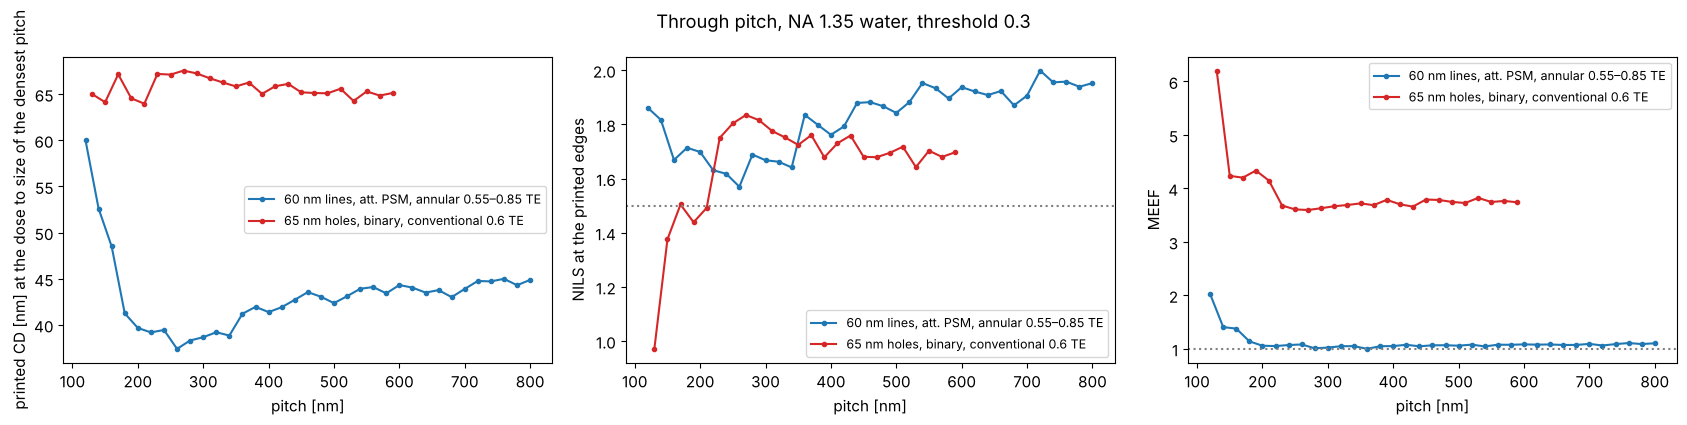

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
pitches_ls = np.arange(120.0, 801.0, 20.0)
pitches_ch = np.arange(130.0, 601.0, 20.0)
for kind, pitches, make, stack, ill, c in (
        ("60 nm lines, att. PSM, annular 0.55–0.85 TE", pitches_ls, lambda p: MaskLayout.lines_spaces(p, 60.0),
         ThinMask.att_psm(0.06), Illumination.annular(0.85, 0.55, polarization="TE"), "C0"),
        ("65 nm holes, binary, conventional 0.6 TE", pitches_ch, lambda p: MaskLayout.contact_holes(p, 65.0),
         ThinMask.binary(), Illumination.conventional(0.6, polarization="TE"), "C3")):
    D = LithoSimulation(make(pitches[0]), stack, ill, water).dose_to_size(threshold=0.3)
    cd, nl, meef = [], [], []
    for p in pitches:
        sim = LithoSimulation(make(p), stack, ill, water)
        cd.append(sim.cd(0.3, D)); nl.append(sim.nils(0.3, D)); meef.append(sim.meef(0.3, D))
    axes[0].plot(pitches, cd, "o-", ms=3, color=c, label=kind)
    axes[1].plot(pitches, nl, "o-", ms=3, color=c, label=kind)
    axes[2].plot(pitches, meef, "o-", ms=3, color=c, label=kind)
axes[0].set_ylabel("printed CD [nm] at the dose to size of the densest pitch")
axes[1].set_ylabel("NILS at the printed edges"); axes[2].set_ylabel("MEEF")
for ax in axes:
    ax.set_xlabel("pitch [nm]"); ax.legend(fontsize=9)
axes[1].axhline(1.5, color="gray", ls=":"); axes[2].axhline(1, color="gray", ls=":")
fig.suptitle("Through pitch, NA 1.35 water, threshold 0.3")
fig.tight_layout()

## 4. Mask stacks: thin mask, thin films and a boundary layer

`ThinMask` sets the transmissions by hand (Kirchhoff approximation).
`FilmMask` computes them from the absorber material with
`pyoptics.thin_films`: absorber layers on the fused silica blank, light
from the blank into air, the clear area as bare blank; the transmission is
taken relative to the clear area at the same plane. A MoSi absorber
($n \approx 2.34 + 0.59i$ at 193 nm) of about 70 nm gives the familiar 6 %
attenuated PSM; the phase follows from the thickness and is tuned to 180°.
Chrome ($n \approx 0.84 + 1.65i$) of 70 nm is practically opaque.

The film transmissions depend on the angle of incidence at the mask
($n\sin\theta = \mathrm{NA}\,|s|/M$, $M = 4$) and on TE/TM; the
differences are small at the mask side of a 4x system, but they come for
free.

MoSi 73.5 nm: T = 5.22 %, phase = 179.5°
Cr 70.0 nm: T = 0.09 %, phase = 325.8°
MoSi 68.0 nm: T = 6.38 %, phase = 165.5°


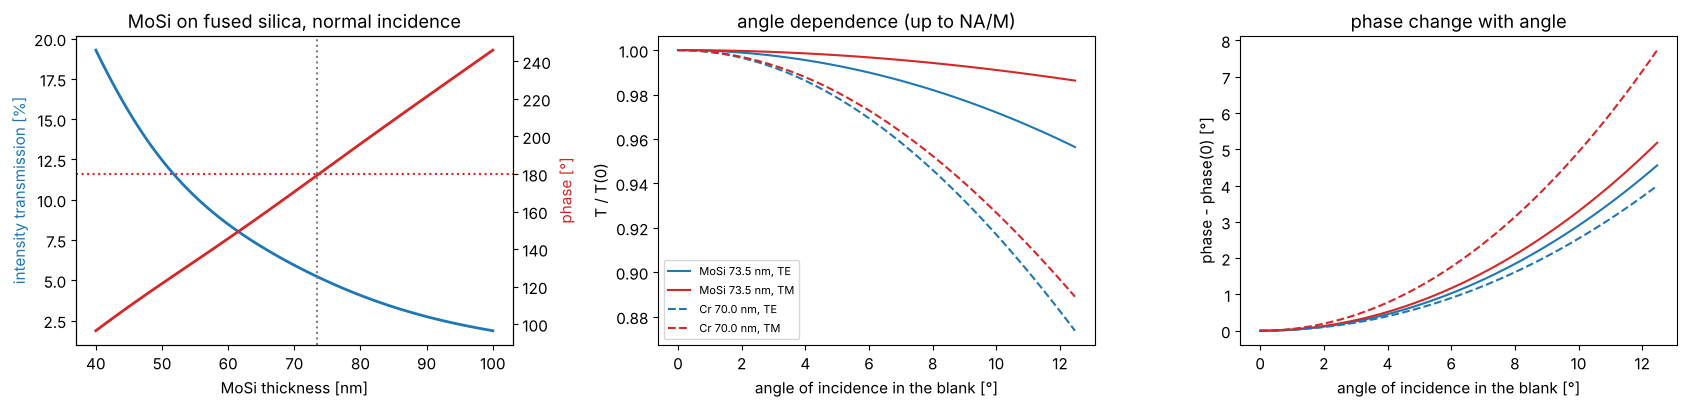

In [6]:
d = np.linspace(40, 100, 121)
T, ph = [], []
for t in d:
    ta, tc = film_mask("MoSi", t).transmissions(0.0, wl)
    r = ta[0]/tc[0]; T.append(abs(r)**2); ph.append(np.degrees(np.angle(r)) % 360)
T, ph = np.array(T), np.array(ph)
d_180 = d[np.argmin(np.abs(ph - 180))]
mosi = film_mask("MoSi", d_180)
chrome = film_mask("Cr", 70.0)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(d, 100*T, lw=2, color="C0"); axes[0].set_ylabel("intensity transmission [%]", color="C0")
ax2 = axes[0].twinx(); ax2.plot(d, ph, lw=2, color="C3"); ax2.set_ylabel("phase [°]", color="C3")
ax2.axhline(180, color="C3", ls=":"); axes[0].axvline(d_180, color="gray", ls=":")
axes[0].set_xlabel("MoSi thickness [nm]"); axes[0].set_title("MoSi on fused silica, normal incidence")
sin_t = np.linspace(0, NA/(4*1.563), 50)
for f, ls in ((mosi, "-"), (chrome, "--")):
    ta, tc = f.transmissions(sin_t, wl)
    r = ta/tc
    for i, (pol, c) in enumerate((("TE", "C0"), ("TM", "C3"))):
        axes[1].plot(np.degrees(np.arcsin(sin_t)), abs(r[i])**2/abs(r[i, 0])**2, ls, color=c, label=f"{f.name}, {pol}")
        axes[2].plot(np.degrees(np.arcsin(sin_t)), np.degrees(np.angle(r[i]/r[i, 0])), ls, color=c, label=f"{f.name}, {pol}")
axes[1].set_xlabel("angle of incidence in the blank [°]"); axes[1].set_ylabel("T / T(0)")
axes[2].set_xlabel("angle of incidence in the blank [°]"); axes[2].set_ylabel("phase - phase(0) [°]")
axes[1].legend(fontsize=8); axes[1].set_title("angle dependence (up to NA/M)")
axes[2].set_title("phase change with angle")
fig.tight_layout()
for f in (mosi, chrome, film_mask("MoSi", 68.0)):
    ta, tc = f.transmissions(0.0, wl); r = ta[0]/tc[0]
    print(f"{f.name}: T = {100*abs(r)**2:.2f} %, phase = {np.degrees(np.angle(r)) % 360:.1f}°")

The phase of an attenuated PSM matters through focus: a phase error makes
the Bossung curves asymmetric (a focus shift that depends on the pitch); for
the 165° mask the effect is small but visible at the ends of the focus range.
Below: 45 nm lines (dark on clear field, 6 % att. PSM) at pitch 180 nm,
annular TE illumination; thin mask with 180°, film masks with 165° (68 nm
MoSi) and 180°, and a binary chrome film mask. For each mask the dose sizes
the lines at best focus.

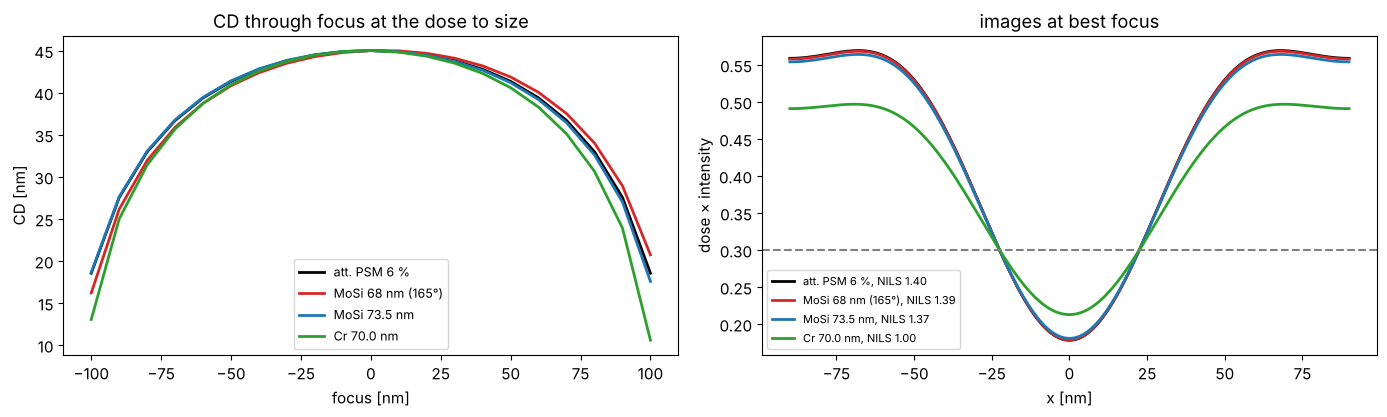

In [7]:
iso_ish = MaskLayout.lines_spaces(180.0, 45.0)
ill = Illumination.annular(0.9, 0.6, polarization="TE")
foci = np.linspace(-150, 150, 31)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for stack, c in ((ThinMask.att_psm(0.06), "k"), (film_mask("MoSi", 68.0, name="MoSi 68 nm (165°)"), "C3"),
                 (mosi, "C0"), (chrome, "C2")):
    sim = LithoSimulation(iso_ish, stack, ill, water)
    D = sim.dose_to_size(threshold=0.3)
    cd = sim.fem(foci, [D], 0.3)[0]
    axes[0].plot(foci, cd, color=c, lw=2, label=f"{stack.name}")
    u, I = sim.cut(401)
    axes[1].plot(u, D*I, color=c, lw=2, label=f"{stack.name}, NILS {sim.nils(0.3, D):.2f}")
axes[0].set_xlabel("focus [nm]"); axes[0].set_ylabel("CD [nm]"); axes[0].legend(fontsize=9)
axes[0].set_title("CD through focus at the dose to size")
axes[1].axhline(0.3, color="gray", ls="--"); axes[1].set_xlabel("x [nm]"); axes[1].set_ylabel("dose × intensity")
axes[1].legend(fontsize=8); axes[1].set_title("images at best focus")
fig.tight_layout()

**Boundary layer.** A real absorber is not thin: at 45 nm wafer CD the
absorber (70 nm) is about as thick as the feature on the mask (180 nm)
is wide, and the field near its edges differs from the Kirchhoff
assumption, differently for TE and TM. The boundary layer model
(Tirapu-Azpiroz and Yablonovitch) puts a strip of width $w$ with a complex,
polarization dependent transmission on every edge; its parameters are
calibrated against rigorous (e.g. RCWA or FDTD) simulations, which this
toolbox does not contain. The values below are illustrative only. Edges
along $y$ see $E_y$ as TE and $E_x$ as TM, so the printed CD of vertical
lines now depends on the polarization, and differently for different
pitches. With $t_\mathrm{TE} = t_\mathrm{TM} = t_\mathrm{absorber}$ the
strips are a plain bias of $w$ (checked in the tests). Plotted: the change
of the printed CD of 60 nm binary lines by the boundary layer, at the dose
that sizes the Kirchhoff mask at each pitch.

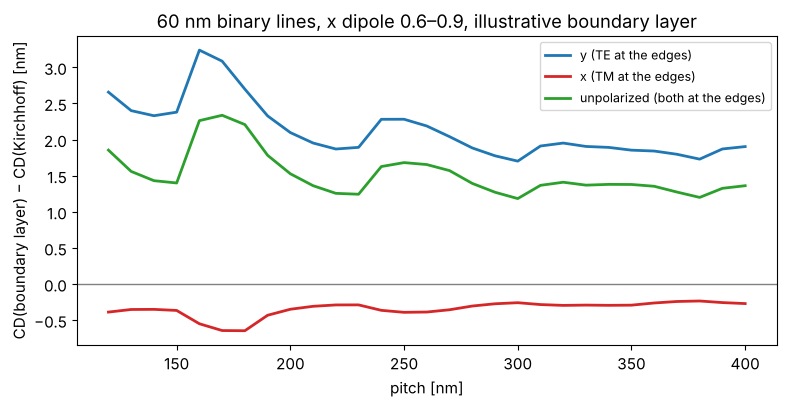

In [8]:
bl = BoundaryLayer(4.0, t_TE=0.25*np.exp(0.4j), t_TM=0.55*np.exp(-0.3j))
pitches = np.arange(120.0, 401.0, 10.0)
fig, ax = plt.subplots(figsize=(8, 4.2))
for pol, c in (("y", "C0"), ("x", "C3"), ("unpolarized", "C2")):
    ill = Illumination.dipole(0.9, 0.6, polarization=pol)
    d_cd = []
    for p in pitches:
        kirchhoff = LithoSimulation(MaskLayout.lines_spaces(p, 60.0), ThinMask.binary(), ill, water)
        D = kirchhoff.dose_to_size(threshold=0.3)
        d_cd.append(kirchhoff.with_(stack=ThinMask.binary(boundary_layer=bl)).cd(0.3, D) - 60.0)
    ax.plot(pitches, d_cd, color=c, lw=2, label=f"{pol} ({'TE' if pol == 'y' else 'TM' if pol == 'x' else 'both'} at the edges)")
ax.axhline(0, color="gray", lw=1)
ax.set_xlabel("pitch [nm]"); ax.set_ylabel("CD(boundary layer) − CD(Kirchhoff) [nm]"); ax.legend(fontsize=9)
ax.set_title("60 nm binary lines, x dipole 0.6–0.9, illustrative boundary layer")
fig.tight_layout()

## 5. Images in the resist: `WaferStack`

Without a wafer stack, `LithoSimulation` returns the aerial image in the
immersion liquid. With `WaferStack(resist=(n, k, d), below=[BARC...],
substrate=(n, k))` each plane wave is split into TE and TM, transmitted
into the resist with the coefficients of `thin_films` and reflected at the
layers below; downward and upward waves interfere to standing waves. The
resist here: $n = 1.70 + 0.03i$, 100 nm, on silicon ($0.88 + 2.78i$), with
or without a BARC ($1.82 + 0.34i$). The BARC thickness is chosen for low
reflectivity at the angles of the dense lines below. `focus` is the
position of the resist top relative to the focal plane, `depth` the
position in the resist.

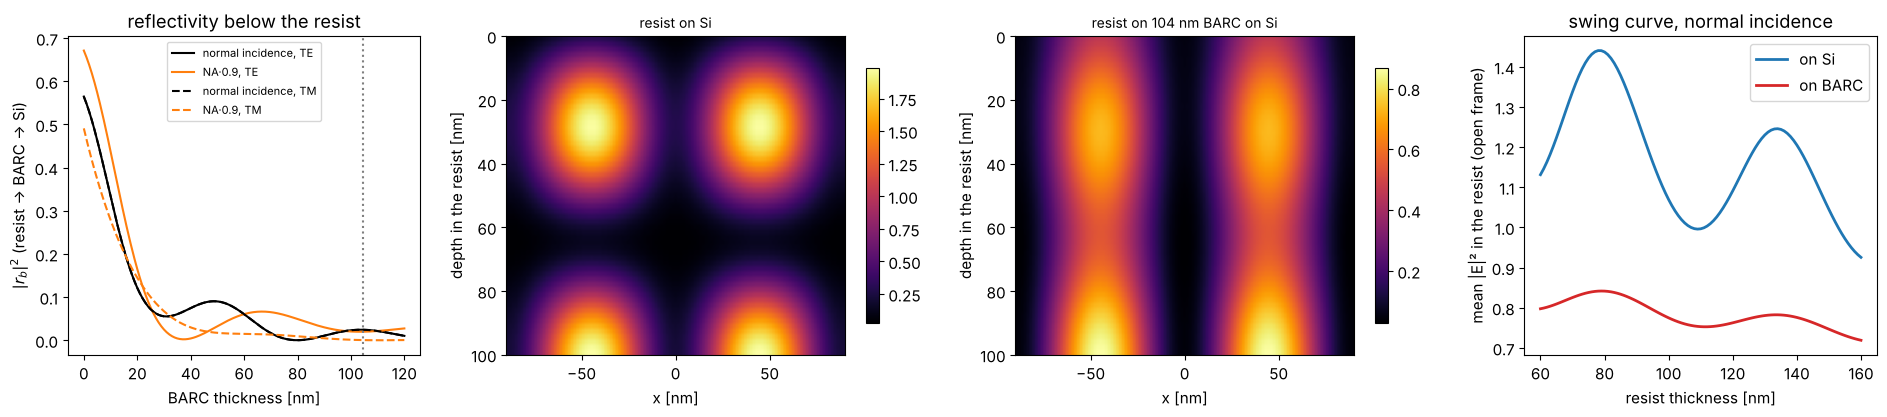

In [9]:
k0 = 2*np.pi/wl
resist = layer("resist", 100.0)
tb = np.linspace(0, 120, 241)
k_perp = k0*np.array([0.0, 0.9*NA])
R = np.array([[np.abs(WaferStack(resist, below=[layer("BARC", t)] if t > 0 else []).coefficients(k_perp, k0, n_w, pol)[2])**2
               for pol in ("TE", "TM")] for t in tb])
t_barc = tb[np.argmin(R[:, 0, 1] + R[:, 1, 1])]
no_barc = WaferStack(resist, name="resist on Si")
barc = WaferStack(resist, below=[layer("BARC", t_barc)], name=f"resist on {t_barc:.0f} nm BARC on Si")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), gridspec_kw={"width_ratios": [1, 1.2, 1.2, 1]})
for i, (pol, ls) in enumerate((("TE", "-"), ("TM", "--"))):
    axes[0].plot(tb, R[:, i, 0], ls, color="k", label=f"normal incidence, {pol}")
    axes[0].plot(tb, R[:, i, 1], ls, color="C1", label=f"NA·0.9, {pol}")
axes[0].axvline(t_barc, color="gray", ls=":")
axes[0].set_xlabel("BARC thickness [nm]"); axes[0].set_ylabel("$|r_b|^2$ (resist → BARC → Si)")
axes[0].legend(fontsize=8); axes[0].set_title("reflectivity below the resist")

sim = LithoSimulation(MaskLayout.lines_spaces(90.0, 45.0), ThinMask.binary(),
                      Illumination.dipole_for_pitch(90.0, wl, NA, polarization="y"), water)
x = np.linspace(-90, 90, 121)
depths = np.linspace(0, resist[2], 61)
for ax, w in zip(axes[1:3], (no_barc, barc)):
    s = sim.with_(wafer=w, normalize=False)
    xz = np.array([s.image(x, depth=z) for z in depths])
    im = ax.imshow(xz, extent=[x[0], x[-1], depths[-1], depths[0]], aspect="auto", cmap="inferno")
    ax.set_xlabel("x [nm]"); ax.set_ylabel("depth in the resist [nm]"); ax.set_title(w.name, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8)
# swing curve: mean intensity in the resist (open frame) vs. resist thickness
d_r = np.linspace(60, 160, 101)
for w_below, c, label in (([], "C0", "on Si"), ([layer("BARC", t_barc)], "C3", "on BARC")):
    swing = []
    for dd in d_r:
        st = WaferStack(layer("resist", dd), below=w_below)
        s = sim.with_(wafer=st, normalize=False, illumination=Illumination.coherent(polarization="y"))
        swing.append(np.mean([s.open_frame(depth=z) for z in np.linspace(0, dd, 15)]))
    axes[3].plot(d_r, swing, color=c, lw=2, label=label)
axes[3].set_xlabel("resist thickness [nm]"); axes[3].set_ylabel("mean |E|² in the resist (open frame)")
axes[3].set_title("swing curve, normal incidence"); axes[3].legend()
fig.tight_layout()

Without BARC the silicon reflects about half of the light back and the
image has strong standing waves across the depth (and the absorbed dose
swings with the resist thickness); the BARC removes most of them. Inside
the resist ($n = 1.7$) the angles are smaller than in water, which helps TM
light, and TE and TM are transmitted differently into the resist:

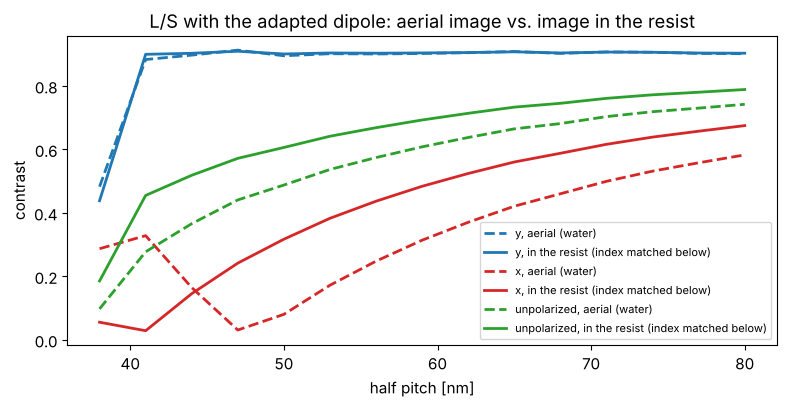

In [10]:
semi = WaferStack((1.70, 0.0, 1E4), substrate=(1.70, 0.0), name="semi-infinite resist")
hp = np.arange(38.0, 81.0, 3.0)
fig, ax = plt.subplots(figsize=(8, 4.2))
for pol, c in (("y", "C0"), ("x", "C3"), ("unpolarized", "C2")):
    for w, ls, label in ((None, "--", "aerial (water)"), (semi, "-", "in the resist (index matched below)")):
        V = []
        for h in hp:
            s = LithoSimulation(MaskLayout.lines_spaces(2*h, h), ThinMask.binary(),
                                Illumination.dipole_for_pitch(2*h, wl, NA, polarization=pol), water, wafer=w)
            V.append(metrics.contrast(s.image(np.linspace(-h, h, 101), depth=10.0)))
        ax.plot(hp, V, ls, color=c, lw=2, label=f"{pol}, {label}")
ax.set_xlabel("half pitch [nm]"); ax.set_ylabel("contrast"); ax.legend(fontsize=8)
ax.set_title("L/S with the adapted dipole: aerial image vs. image in the resist")
fig.tight_layout()

## 6. Focus-exposure matrix, Bossung curves and process windows

`LithoSimulation.fem(foci, doses, threshold)` returns the CD of the first
feature for every focus and dose (constant threshold resist). From it,
`metrics.process_window()` gives the in-spec dose range per focus (CD
within ±10 %) and `metrics.el_dof()` the exposure latitude vs. depth of
focus. Here: 65 nm contact holes at 130 nm pitch with a quasar, binary
and 6 % att. PSM, with azimuthal (TE), radial (TM) and no polarization.

binary, TE: dose to size 1.63, EL 18.4 %, DOF at 5 % EL 200 nm


att. PSM 6 %, TE: dose to size 2.25, EL 12.7 %, DOF at 5 % EL 160 nm


att. PSM 6 %, TM: dose to size 2.25, EL 25.6 %, DOF at 5 % EL 260 nm


att. PSM 6 %, unpolarized: dose to size 2.25, EL 19.2 %, DOF at 5 % EL 220 nm


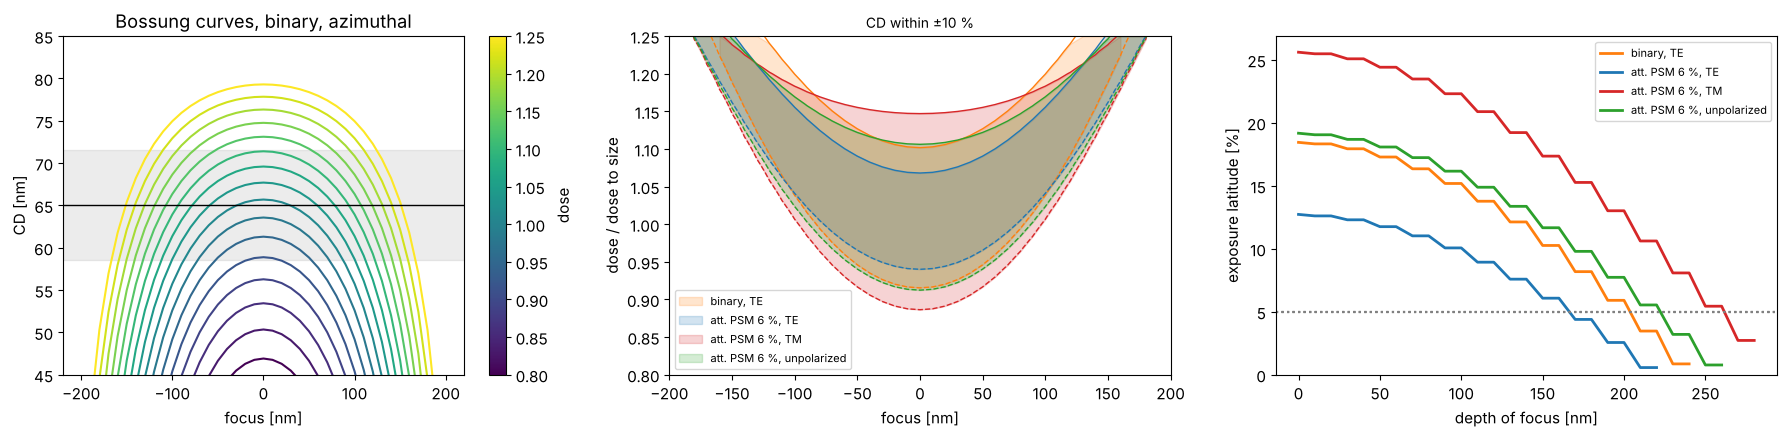

In [11]:
foci = np.linspace(-200, 200, 41)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for stack, pol, c in ((ThinMask.binary(), "TE", "C1"), (ThinMask.att_psm(0.06), "TE", "C0"),
                      (ThinMask.att_psm(0.06), "TM", "C3"), (ThinMask.att_psm(0.06), "unpolarized", "C2")):
    sim = LithoSimulation(ch65, stack, Illumination.quasar(0.95, 0.7, polarization=pol), water)
    D0 = sim.dose_to_size(threshold=0.3)
    doses = D0*np.linspace(0.8, 1.25, 46)
    cd = sim.fem(foci, doses, 0.3)
    if stack.name.startswith("binary"):
        plot_bossung(foci, doses/D0, cd, ax=axes[0], cd_target=65.0, every=3)
        axes[0].set_title("Bossung curves, binary, azimuthal"); axes[0].set_xlabel("focus [nm]"); axes[0].set_ylabel("CD [nm]")
        axes[0].set_ylim(45, 85)
    label = f"{stack.name}, {pol}"
    dof, el = plot_process_window(foci, doses/D0, cd, 65.0, 0.1, axes=axes[1:], color=c, label=label, el_min=0.05)
    print(f"{label}: dose to size {D0:.2f}, EL {100*el[0]:.1f} %, DOF at 5 % EL {metrics.dof_at_el(dof, el, 0.05):.0f} nm")
axes[1].set_xlabel("focus [nm]"); axes[1].set_ylabel("dose / dose to size"); axes[1].legend(fontsize=8)
axes[2].set_xlabel("depth of focus [nm]"); axes[2].legend(fontsize=8)
fig.tight_layout()

Azimuthal polarization is not automatically the best choice. With the
att. PSM the zeroth order of the hole array almost vanishes,
$c_{00} = t + (1 - t)(\mathrm{cd}/p)^2 \approx 0.07$ for $t = -0.245$, and the
image of a quasar pole at $s \propto (1, 1)$ is dominated by the orders
$(-1, 0)$ and $(0, -1)$. They sit on opposite sides of the pupil along the
anti-diagonal, so their plane of incidence is the anti-diagonal plane, which
contains the azimuthal polarization $(-1, 1)/\sqrt2$ of the pole: for this
pair azimuthal is TM, and at about 47° in water its contrast is reversed.
Radial polarization is TE for the pair and gives the larger window. With
the binary mask the zeroth order is strong and pairs with the first orders
along x and y, for which both polarizations are mixed.

## 7. Aberrations

`Projector(..., zernikes={j: c})` adds Fringe Zernike aberrations (in
waves) to the pupil. Spherical aberration ($Z_9$) shifts the best focus
differently for different pitches, which shrinks the common process
window; coma ($Z_7$, x) shifts the image of lines sideways (placement
error), again depending on the pitch.

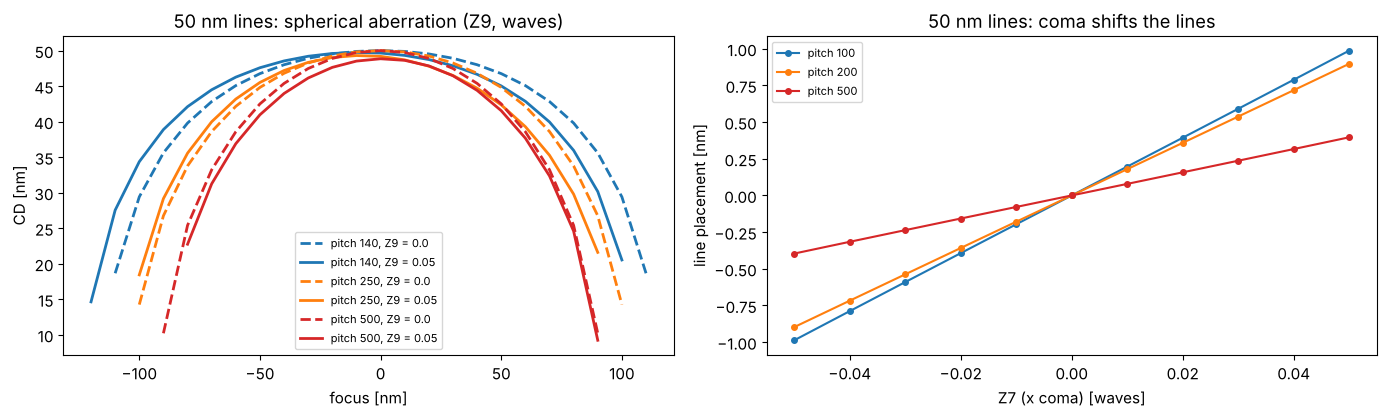

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ill = Illumination.annular(0.9, 0.6, polarization="TE")
foci = np.linspace(-150, 150, 31)
for p, c in ((140.0, "C0"), (250.0, "C1"), (500.0, "C3")):
    for z9, ls in ((0.0, "--"), (0.05, "-")):
        sim = LithoSimulation(MaskLayout.lines_spaces(p, 50.0), ThinMask.att_psm(0.06), ill, water.with_(zernikes={9: z9}))
        D = LithoSimulation(MaskLayout.lines_spaces(p, 50.0), ThinMask.att_psm(0.06), ill, water).dose_to_size(threshold=0.3)
        axes[0].plot(foci, sim.fem(foci, [D], 0.3)[0], ls, color=c, lw=2, label=f"pitch {p:.0f}, Z9 = {z9}")
axes[0].set_xlabel("focus [nm]"); axes[0].set_ylabel("CD [nm]"); axes[0].legend(fontsize=8)
axes[0].set_title("50 nm lines: spherical aberration (Z9, waves)")
z7 = np.linspace(-0.05, 0.05, 11)
for p, c in ((100.0, "C0"), (200.0, "C1"), (500.0, "C3")):
    shifts = []
    for z in z7:
        sim = LithoSimulation(MaskLayout.lines_spaces(p, 50.0), ThinMask.att_psm(0.06), ill, water.with_(zernikes={7: z}))
        D = sim.with_(projector=water).dose_to_size(threshold=0.3)
        u, I = sim.cut(801)
        left, right = metrics.feature_edges(u, D*I, 0.3)
        shifts.append((left + right)/2)
    axes[1].plot(z7, shifts, "o-", color=c, ms=4, label=f"pitch {p:.0f}")
axes[1].set_xlabel("Z7 (x coma) [waves]"); axes[1].set_ylabel("line placement [nm]")
axes[1].set_title("50 nm lines: coma shifts the lines"); axes[1].legend(fontsize=8)
fig.tight_layout()

## 8. Apodization

A real projection lens does not transmit all directions equally: coatings
and absorption in the glass make the pupil transmission fall off towards
the rim or vary across the pupil (apodization). The pupil function is
$A(P_x, P_y)\,\exp(i\,2\pi W(P_x, P_y))$; `Projector` takes the amplitude
transmission as apodization Zernikes, Fringe Zernike coefficients $a_j$
with $A = 1 + \sum_j a_j Z_j(P_x, P_y)$ (the default,
`apodization_model="linear"`; $A$ must stay non-negative inside the
pupil, and a constant cancels in the normalized images), or as any
function `apodization(P_x, P_y)`. Optionally, `apodization_model="log"`
reads the coefficients as log amplitude, $A = \exp(\sum_j a_j Z_j)$:
positive for any coefficients, and the coefficients of two elements add
like wavefront Zernikes; for small $a_j$ both models agree (dashed below:
the same $a_4 = -0.25$ as log amplitude, almost the same fall-off). A rotationally symmetric fall-off ($Z_4$, $Z_9$)
changes the balance of the diffraction orders, depending on where they
land in the pupil. For the clear field att. PSM lines below with the
annular source, the strong zeroth order passes near the rim (at the
radius of the source points) and is damped most, while the first orders
of the dense pitches land closer to the center: the orders become more
balanced and the NILS even rises a little, at the price of dose (the
image is normalized to the open frame, which loses light, too). For other
layouts and sources the same apodization can lower the NILS; the point is
that it changes the images through pitch, i.e. the optical proximity
effect that OPC is tuned to. An asymmetric apodization
($Z_2$, a transmission tilt along x) weights the two sides of the pupil
differently; the image then walks sideways through focus, like a
telecentricity error, which is a placement error at any defocus.

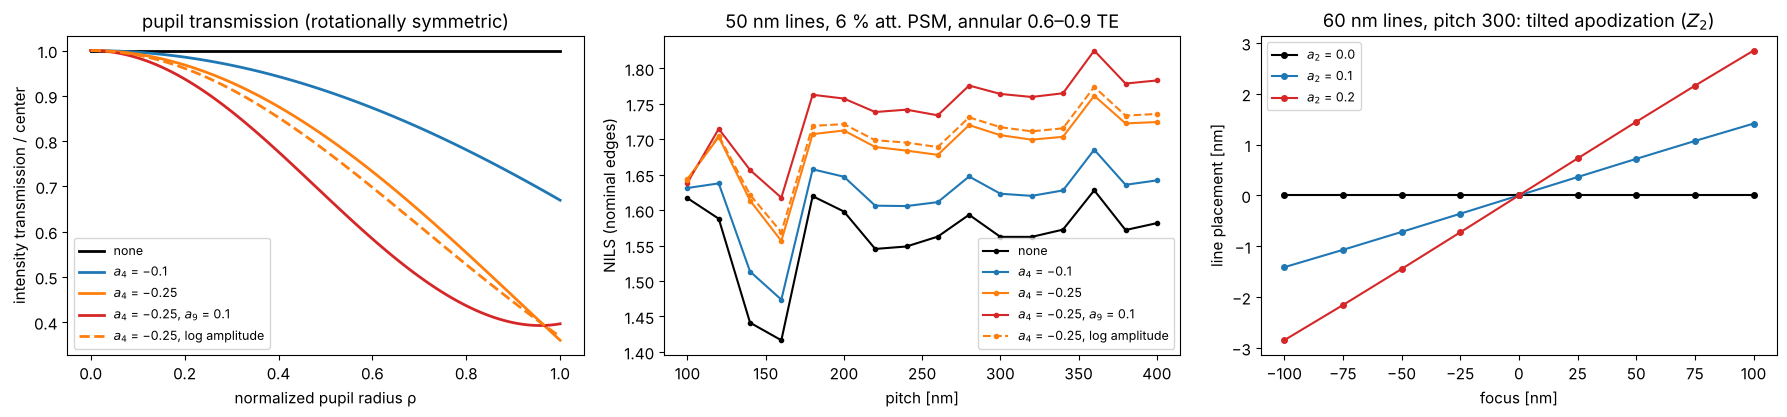

In [13]:
rho = np.linspace(0, 1, 101)
apos = {"none": ({}, "linear"), "$a_4$ = −0.1": ({4: -0.1}, "linear"),
        "$a_4$ = −0.25": ({4: -0.25}, "linear"), "$a_4$ = −0.25, $a_9$ = 0.1": ({4: -0.25, 9: 0.1}, "linear"),
        "$a_4$ = −0.25, log amplitude": ({4: -0.25}, "log")}
ill = Illumination.annular(0.9, 0.6, polarization="TE")
pitches = np.arange(100.0, 401.0, 20.0)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for (name, (z, model)), c in zip(apos.items(), ("k", "C0", "C1", "C3", "C1")):
    proj = water.with_(apodization_zernikes=z, apodization_model=model)
    ls = "--" if model == "log" else "-"
    T = proj.pupil_amplitude(rho, 0*rho)**2
    axes[0].plot(rho, T/T[0], ls, color=c, lw=2, label=name)
    nl = [LithoSimulation(MaskLayout.lines_spaces(p, 50.0), ThinMask.att_psm(0.06), ill, proj).nils()
          for p in pitches]
    axes[1].plot(pitches, nl, "o" + ls, ms=3, color=c, label=name)
axes[0].set_xlabel("normalized pupil radius ρ"); axes[0].set_ylabel("intensity transmission / center")
axes[0].set_title("pupil transmission (rotationally symmetric)"); axes[0].legend(fontsize=9)
axes[1].set_xlabel("pitch [nm]"); axes[1].set_ylabel("NILS (nominal edges)"); axes[1].legend(fontsize=9)
axes[1].set_title("50 nm lines, 6 % att. PSM, annular 0.6–0.9 TE")
foci = np.linspace(-150, 150, 13)
layout = MaskLayout.lines_spaces(300.0, 60.0)
for a2, c in ((0.0, "k"), (0.1, "C0"), (0.2, "C3")):
    sim = LithoSimulation(layout, ThinMask.att_psm(0.06), ill, water.with_(apodization_zernikes={2: a2}))
    D = sim.dose_to_size(threshold=0.3)
    shift = []
    for f in foci:
        u, I = sim.cut(801, focus=f)
        left, right = metrics.feature_edges(u, D*I, 0.3)
        shift.append((left + right)/2)
    axes[2].plot(foci, shift, "o-", ms=4, color=c, label=f"$a_2$ = {a2}")
axes[2].set_xlabel("focus [nm]"); axes[2].set_ylabel("line placement [nm]"); axes[2].legend(fontsize=9)
axes[2].set_title("60 nm lines, pitch 300: tilted apodization ($Z_2$)")
fig.tight_layout()

### CD through pitch with apodization

What apodization does in practice shows up in the proximity curve, the
printed CD through pitch at a fixed dose and mask. Here: 60 nm lines on
a 6 % att. PSM (no OPC, same mask CD at every pitch), annular 0.5–0.8 TE.
For each pupil, the dose is set so that the densest pitch (120 nm)
prints at 60 nm, which is how the dose is anchored in a fab. The orders
of each pitch land at different pupil radii, so a radial fall-off of the
transmission changes the balance of the orders differently for each
pitch: relative to the dense anchor, the CD at the other pitches moves by
up to a few nm. An OPC model calibrated with a different apodization
(or none) leaves exactly this error behind. The right panel shows that
the CD change is nearly linear in the apodization coefficient for most
pitches, so it can be described by a sensitivity per Zernike and pitch.

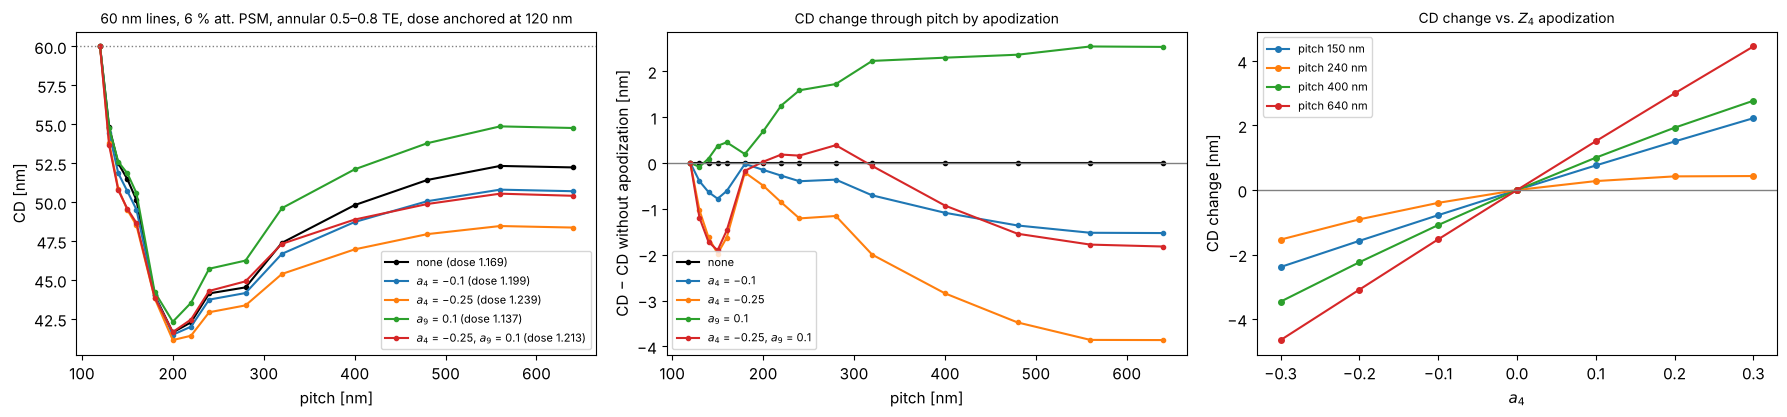

In [14]:
ill = Illumination.annular(0.8, 0.5, polarization="TE")
pitches = np.array([120, 130, 140, 150, 160, 180, 200, 220, 240, 280, 320, 400, 480, 560, 640.0])
apos = {"none": {}, "$a_4$ = −0.1": {4: -0.1}, "$a_4$ = −0.25": {4: -0.25}, "$a_9$ = 0.1": {9: 0.1},
        "$a_4$ = −0.25, $a_9$ = 0.1": {4: -0.25, 9: 0.1}}


def proximity_curve(proj, pitches, cd=60.0, threshold=0.3):
    """CD through pitch at the dose that sizes the first (densest) pitch."""
    sims = [LithoSimulation(MaskLayout.lines_spaces(p, cd), ThinMask.att_psm(0.06), ill, proj)
            for p in pitches]
    D = sims[0].dose_to_size(threshold=threshold)
    return np.array([s.cd(threshold, D) for s in sims]), D


fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
cd_ref, _ = proximity_curve(water, pitches)
for (name, z), c in zip(apos.items(), ("k", "C0", "C1", "C2", "C3")):
    cd_p, D = proximity_curve(water.with_(apodization_zernikes=z), pitches)
    axes[0].plot(pitches, cd_p, "o-", ms=3, color=c, label=f"{name} (dose {D:.3f})")
    axes[1].plot(pitches, cd_p - cd_ref, "o-", ms=3, color=c, label=name)
axes[0].axhline(60.0, color="gray", ls=":", lw=1)
axes[0].set_xlabel("pitch [nm]"); axes[0].set_ylabel("CD [nm]"); axes[0].legend(fontsize=8)
axes[0].set_title("60 nm lines, 6 % att. PSM, annular 0.5–0.8 TE, dose anchored at 120 nm", fontsize=10)
axes[1].axhline(0, color="gray", lw=1)
axes[1].set_xlabel("pitch [nm]"); axes[1].set_ylabel("CD − CD without apodization [nm]")
axes[1].set_title("CD change through pitch by apodization", fontsize=10); axes[1].legend(fontsize=8)
a4_vals = np.linspace(-0.3, 0.3, 7)
sel = [150.0, 240.0, 400.0, 640.0]
idx = [list(pitches).index(p) for p in sel]
dcd = np.array([proximity_curve(water.with_(apodization_zernikes={4: a}), pitches[[0] + idx])[0][1:]
                for a in a4_vals]) - cd_ref[idx]
for k, p in enumerate(sel):
    axes[2].plot(a4_vals, dcd[:, k], "o-", ms=4, label=f"pitch {p:.0f} nm")
axes[2].axhline(0, color="gray", lw=1)
axes[2].set_xlabel("$a_4$"); axes[2].set_ylabel("CD change [nm]"); axes[2].legend(fontsize=8)
axes[2].set_title("CD change vs. $Z_4$ apodization", fontsize=10)
fig.tight_layout()

## 9. A simple resist model: blur

The constant threshold model takes the aerial image (or the image in the
resist) as the latent image. Acid diffusion in chemically amplified resists
blurs it; `metrics.gaussian_blur()` convolves a periodic image with a
Gaussian of the diffusion length $\sigma$, which lowers the contrast and
rounds the corners of rectangular contacts.

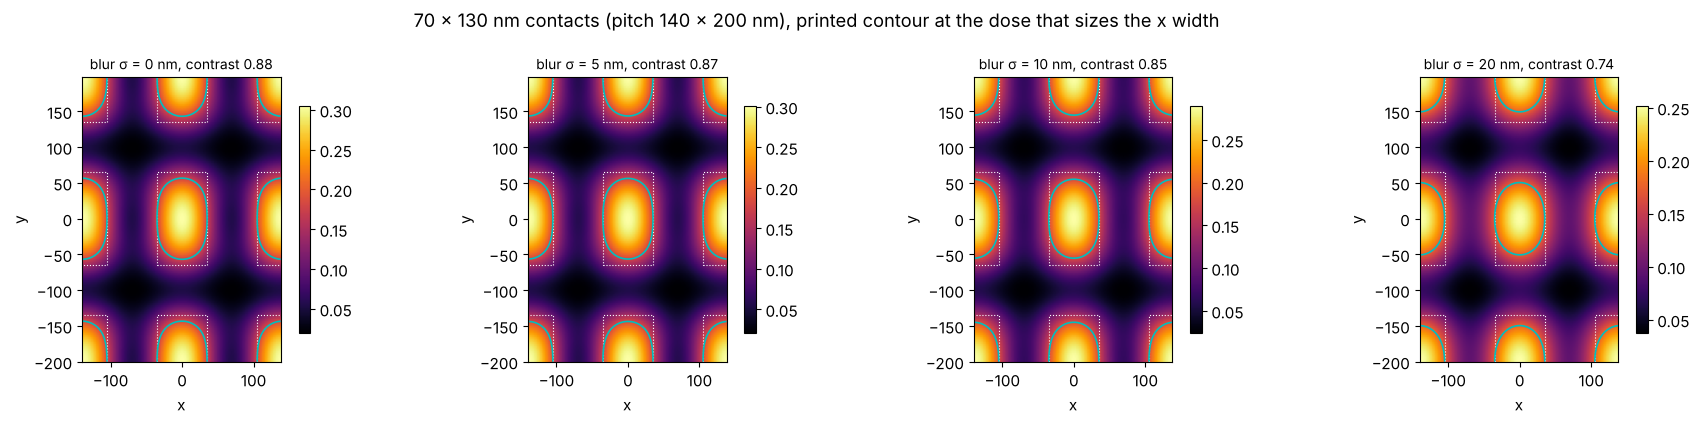

In [15]:
rect = MaskLayout.contact_holes(140.0, 70.0, pitch_y=200.0, cd_y=130.0)
sim = LithoSimulation(rect, ThinMask.att_psm(0.06), Illumination.annular(0.9, 0.5, polarization="TE"), water)
from pyoptics.utils import grid1d
x, y = grid1d(-140, 140, 128), grid1d(-200, 200, 160)
I = sim.image(x, y)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, sig in zip(axes, (0.0, 5.0, 10.0, 20.0)):
    Ib = I if sig == 0 else metrics.gaussian_blur(I, x[1] - x[0], sig, y[1] - y[0])
    D = 0.3/np.mean(np.interp([-35, 35], x, Ib[len(y)//2]))  # size the x width to 70 nm
    plot_image(sim, x, Ib, y, ax=ax, threshold=0.3, dose=D)
    ax.set_title(f"blur σ = {sig:.0f} nm, contrast {metrics.contrast(Ib):.2f}", fontsize=10)
fig.suptitle("70 × 130 nm contacts (pitch 140 × 200 nm), printed contour at the dose that sizes the x width")
fig.tight_layout()

## 10. KrF lithography (248 nm)

Nothing in the toolbox is specific to ArF: the wavelength enters through
the `Projector`, the materials through the stacks. KrF scanners image at
248 nm, dry (NA up to about 0.93, here 0.8), with the KrF set of
`MATERIALS` (approximate values). Below: the MoSi thickness for a 180°
attenuated PSM at both wavelengths, a BARC for a KrF resist on silicon,
and the NILS of lines and spaces against $k_1 = \mathrm{hp}\,\mathrm{NA}/\lambda$
for ArF immersion (NA 1.35), ArF dry (NA 0.93) and KrF dry (NA 0.8) with
the adapted dipole. What matters for the polarization is the angle in the
image space medium, $\sin\theta = \mathrm{NA}\,s_c/n$ with $s_c \approx 0.89$:
ArF dry at NA 0.93 and ArF immersion at NA 1.35 have nearly the same
angles (sin θ ≈ 0.83) and lose the same NILS with unpolarized light (see
also notebook 31, section 5), KrF at NA 0.8 has smaller ones (sin θ ≈
0.71) and loses less. TE light gives the same NILS at the same $k_1$ in all
three systems.

ArF wavelength: 193.0, water: (1.437, 0.0), fused silica: (1.563, 0.0), MoSi: (2.343, 0.586), Cr: (0.84, 1.65), resist: (1.7, 0.03), BARC: (1.82, 0.34), Si: (0.883, 2.778)
KrF wavelength: 248.0, water: None, fused silica: (1.508, 0.0), MoSi: (2.18, 0.48), Cr: (1.9, 1.9), resist: (1.76, 0.01), BARC: (1.5, 0.45), Si: (1.57, 3.565)


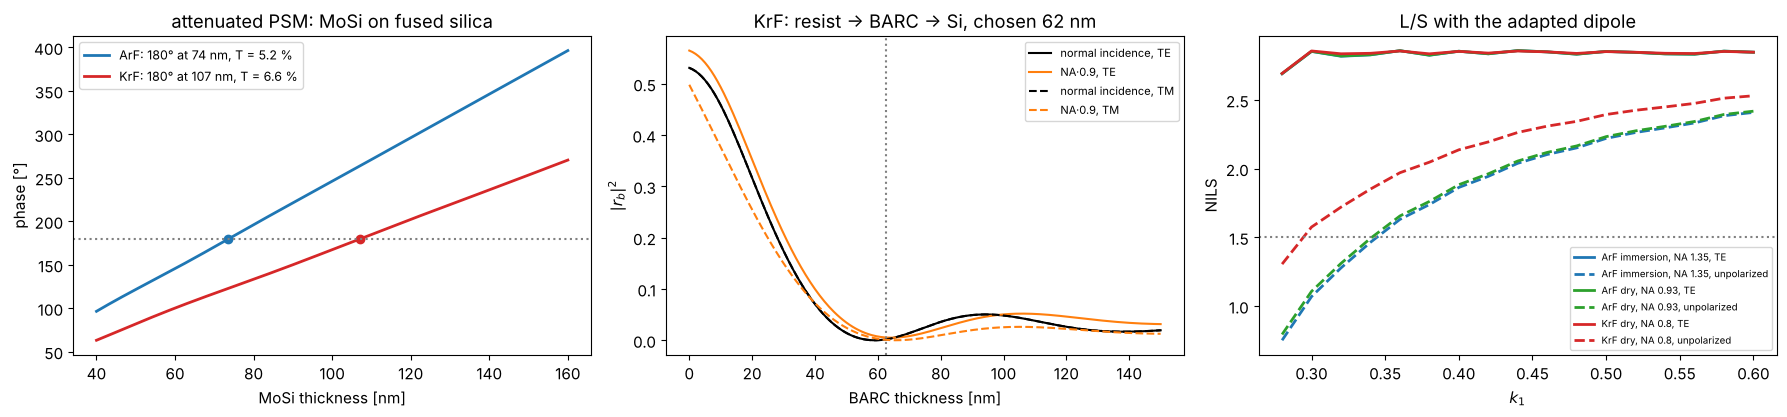

In [16]:
for line in ("ArF", "KrF"):
    print(line, ", ".join(f"{k}: {v}" for k, v in MATERIALS[line].items()))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
d = np.linspace(40, 160, 241)
mosi_180 = {}
for line, c in (("ArF", "C0"), ("KrF", "C3")):
    lam = MATERIALS[line]["wavelength"]
    r = np.array([np.divide(*[t[0] for t in film_mask("MoSi", t, line).transmissions(0.0, lam)]) for t in d])
    ph = np.degrees(np.unwrap(np.angle(r))) % 720
    i180 = np.argmin(np.abs(ph - 180))
    mosi_180[line] = d[i180]
    axes[0].plot(d, ph, color=c, lw=2, label=f"{line}: 180° at {d[i180]:.0f} nm, T = {100*abs(r[i180])**2:.1f} %")
    axes[0].plot(d[i180], 180, "o", color=c)
axes[0].axhline(180, color="gray", ls=":"); axes[0].set_xlabel("MoSi thickness [nm]"); axes[0].set_ylabel("phase [°]")
axes[0].legend(fontsize=9); axes[0].set_title("attenuated PSM: MoSi on fused silica")

krf, lam_k, NA_k = MATERIALS["KrF"], MATERIALS["KrF"]["wavelength"], 0.8
k0_k = 2*np.pi/lam_k
dry_krf = Projector(NA_k, lam_k)
tb = np.linspace(0, 150, 301)
R_k = np.array([[np.abs(WaferStack(layer("resist", 300.0, "KrF"), below=[layer("BARC", t, "KrF")] if t > 0 else [],
                                    substrate=krf["Si"]).coefficients(np.array([0.0, k0_k*0.9*NA_k]), k0_k, 1.0, pol)[2])**2
                 for pol in ("TE", "TM")] for t in tb])
t_barc_k = tb[np.argmin(R_k[:, 0, 1] + R_k[:, 1, 1] + R_k[:, 0, 0])]
for i, (pol, ls) in enumerate((("TE", "-"), ("TM", "--"))):
    axes[1].plot(tb, R_k[:, i, 0], ls, color="k", label=f"normal incidence, {pol}")
    axes[1].plot(tb, R_k[:, i, 1], ls, color="C1", label=f"NA·0.9, {pol}")
axes[1].axvline(t_barc_k, color="gray", ls=":")
axes[1].set_xlabel("BARC thickness [nm]"); axes[1].set_ylabel("$|r_b|^2$"); axes[1].legend(fontsize=8)
axes[1].set_title(f"KrF: resist → BARC → Si, chosen {t_barc_k:.0f} nm")

k1_vals = np.linspace(0.28, 0.6, 17)
for (name, lam, NA_, n_med), c in ((("ArF immersion, NA 1.35", 193.0, 1.35, n_w), "C0"),
                                   (("ArF dry, NA 0.93", 193.0, 0.93, 1.0), "C2"),
                                   (("KrF dry, NA 0.8", lam_k, NA_k, 1.0), "C3")):
    for pol, ls in (("y", "-"), ("unpolarized", "--")):
        nl = []
        for k1 in k1_vals:
            h = k1*lam/NA_
            s = LithoSimulation(MaskLayout.lines_spaces(2*h, h), ThinMask.binary(),
                                Illumination.dipole_for_pitch(2*h, lam, NA_, polarization=pol),
                                Projector(NA_, lam, n_med))
            nl.append(s.nils())
        axes[2].plot(k1_vals, nl, ls, color=c, lw=2, label=f"{name}, {'TE' if pol == 'y' else pol}")
axes[2].axhline(1.5, color="gray", ls=":"); axes[2].set_xlabel("$k_1$"); axes[2].set_ylabel("NILS")
axes[2].legend(fontsize=7); axes[2].set_title("L/S with the adapted dipole")
fig.tight_layout()

A KrF example end to end: 130 nm lines and spaces ($k_1 = 0.42$) on a
6 % MoSi PSM of the thickness found above, annular illumination, imaged
into 300 nm of KrF resist on silicon with and without the BARC, and the
process window of the aerial image.

KrF 130 nm L/S: EL at best focus 18.6 %, DOF at 5 % EL 960 nm


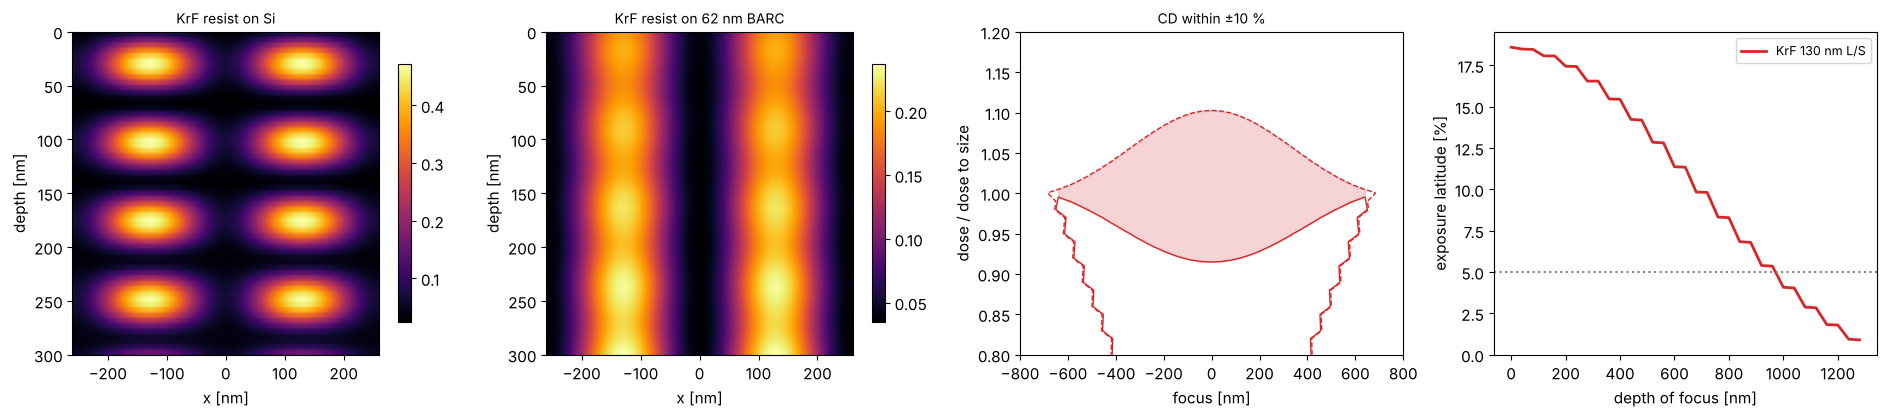

In [17]:
ls130 = MaskLayout.lines_spaces(260.0, 130.0)
sim_k = LithoSimulation(ls130, film_mask("MoSi", mosi_180["KrF"], "KrF"),
                        Illumination.annular(0.85, 0.55, polarization="unpolarized"), dry_krf)
x = np.linspace(-260, 260, 161)
depths = np.linspace(0, 300, 61)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, below, name in zip(axes[:2], ([], [layer("BARC", t_barc_k, "KrF")]), ("on Si", f"on {t_barc_k:.0f} nm BARC")):
    w = WaferStack(layer("resist", 300.0, "KrF"), below=below, substrate=krf["Si"])
    xz = np.array([sim_k.with_(wafer=w, normalize=False).image(x, depth=z) for z in depths])
    im = ax.imshow(xz, extent=[x[0], x[-1], depths[-1], depths[0]], aspect="auto", cmap="inferno")
    ax.set_xlabel("x [nm]"); ax.set_ylabel("depth [nm]"); ax.set_title(f"KrF resist {name}", fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.8)
foci = np.linspace(-800, 800, 41)
D0 = sim_k.dose_to_size(threshold=0.3)
doses = D0*np.linspace(0.8, 1.2, 41)
cd = sim_k.fem(foci, doses, 0.3)
dof, el = plot_process_window(foci, doses/D0, cd, 130.0, 0.1, axes=axes[2:], color="C3",
                              label="KrF 130 nm L/S", el_min=0.05)
axes[2].set_xlabel("focus [nm]"); axes[2].set_ylabel("dose / dose to size"); axes[3].set_xlabel("depth of focus [nm]")
axes[3].legend(fontsize=9)
fig.tight_layout()
print(f"KrF 130 nm L/S: EL at best focus {100*el[0]:.1f} %, DOF at 5 % EL {metrics.dof_at_el(dof, el, 0.05):.0f} nm")

## 11. Astigmatism: vertical and horizontal lines focus differently (KrF)

Astigmatism ($Z_5 = \rho^2\cos 2\phi$, Fringe numbering) curves the
wavefront in opposite directions along $x$ and $y$. Vertical lines (pitch
along $x$) diffract their orders along the $x$ axis of the pupil and see
the wavefront $+a_5\rho^2$, horizontal lines see $-a_5\rho^2$: like a
defocus of opposite sign. Their best foci split by, paraxially,
$\Delta z = 4\,n\lambda\,a_5/\mathrm{NA}^2$ (with $a_5$ in waves; a
defocus $z$ adds the phase $k z\cos\theta \approx \mathrm{const} - k z\,\mathrm{NA}^2\rho^2/(2n)$).
At NA 0.8, $\cos\theta$ is no longer quadratic in $\rho$, and the split is
somewhat smaller than the paraxial value.

The example: KrF, NA 0.8 dry, annular 0.55–0.85 unpolarized, 6 % MoSi
PSM, 150 nm lines at 450 nm pitch, vertical and horizontal, with
$a_5 = 0.05$ waves. Best focus is taken where the contrast peaks; the CD
is evaluated at the dose that sizes the lines without aberration. The
second figure (200 nm binary holes, $a_5 = 0.1$ waves to make the effect
easy to see) shows what this does to contact holes: through focus, the
printed holes stretch along $x$ on one side of best focus and along $y$ on
the other, the classic signature of astigmatism (the holes stay round only
in the middle, where both directions are equally defocused).

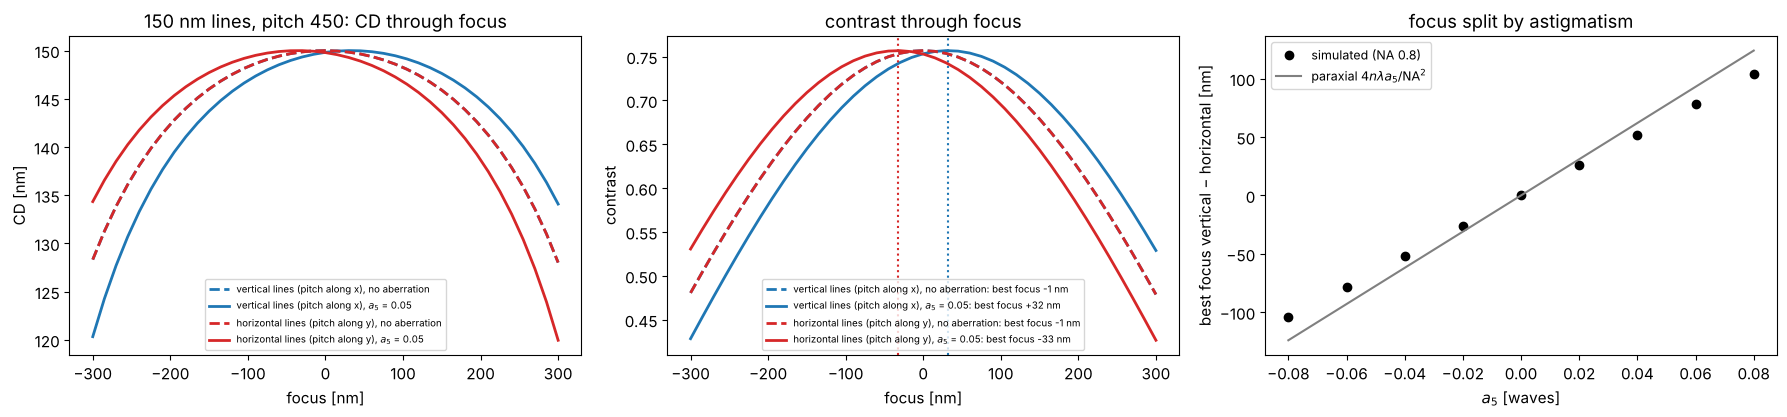

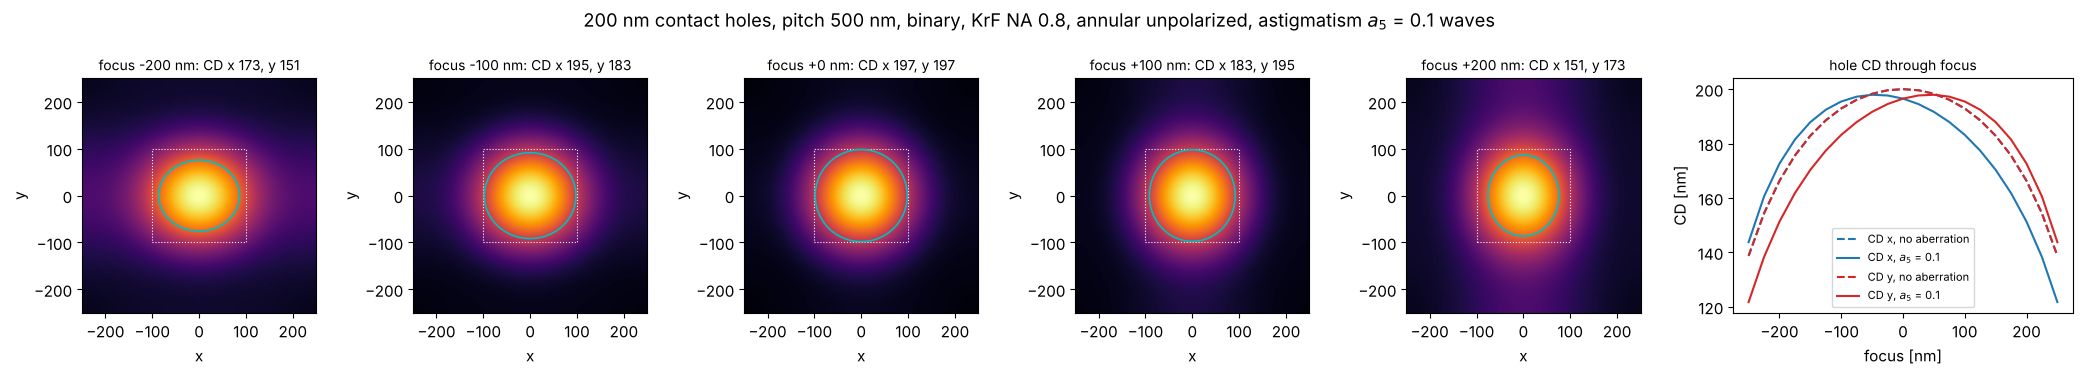

In [18]:
def best_focus(sim, foci):
    """Focus of maximum contrast of the cut through the first feature (local
    quadratic fit)."""

    con = np.array([metrics.contrast(sim.cut(201, focus=f)[1]) for f in foci])
    i = int(np.clip(np.argmax(con), 3, len(foci) - 4))
    p = np.polyfit(foci[i - 3:i + 4], con[i - 3:i + 4], 2)
    return -p[1]/(2*p[0]), con


ill_k = Illumination.annular(0.85, 0.55, polarization="unpolarized")
psm_k = film_mask("MoSi", mosi_180["KrF"], "KrF")
a5 = 0.05
astig = dry_krf.with_(zernikes={5: a5})
foci = np.linspace(-300, 300, 41)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for orient, c, name in (("y", "C0", "vertical lines (pitch along x)"), ("x", "C3", "horizontal lines (pitch along y)")):
    layout = MaskLayout.lines_spaces(450.0, 150.0, orientation=orient)
    ideal = LithoSimulation(layout, psm_k, ill_k, dry_krf)
    D = ideal.dose_to_size(threshold=0.3)
    for proj, ls, label in ((dry_krf, "--", "no aberration"), (astig, "-", f"$a_5$ = {a5}")):
        sim = ideal.with_(projector=proj)
        bf, con = best_focus(sim, foci)
        axes[0].plot(foci, sim.fem(foci, [D], 0.3)[0], ls, color=c, lw=2, label=f"{name}, {label}")
        axes[1].plot(foci, con, ls, color=c, lw=2, label=f"{name}, {label}: best focus {bf:+.0f} nm")
        if proj is astig:
            axes[1].axvline(bf, color=c, ls=":")
axes[0].set_xlabel("focus [nm]"); axes[0].set_ylabel("CD [nm]"); axes[0].legend(fontsize=7)
axes[0].set_title("150 nm lines, pitch 450: CD through focus")
axes[1].set_xlabel("focus [nm]"); axes[1].set_ylabel("contrast"); axes[1].legend(fontsize=7)
axes[1].set_title("contrast through focus")

a5_vals = np.linspace(-0.08, 0.08, 9)
split = []
for a in a5_vals:
    proj = dry_krf.with_(zernikes={5: a})
    bfs = [best_focus(LithoSimulation(MaskLayout.lines_spaces(450.0, 150.0, orientation=o), psm_k, ill_k, proj),
                      np.linspace(-200, 200, 41))[0] for o in ("y", "x")]
    split.append(bfs[0] - bfs[1])
axes[2].plot(a5_vals, split, "o", color="k", label="simulated (NA 0.8)")
axes[2].plot(a5_vals, 4*lam_k*a5_vals/NA_k**2, "-", color="gray", label="paraxial $4n\\lambda a_5/\\mathrm{NA}^2$")
axes[2].set_xlabel("$a_5$ [waves]"); axes[2].set_ylabel("best focus vertical − horizontal [nm]")
axes[2].legend(fontsize=9); axes[2].set_title("focus split by astigmatism")
fig.tight_layout()

holes_k = MaskLayout.contact_holes(500.0, 200.0)
sim_h = LithoSimulation(holes_k, ThinMask.binary(), ill_k, dry_krf)
D_h = sim_h.dose_to_size(threshold=0.3)
a5_h = 0.1
s_h = sim_h.with_(projector=dry_krf.with_(zernikes={5: a5_h}))
x = np.linspace(-250, 250, 101)
fig, axes = plt.subplots(1, 6, figsize=(21, 3.8), gridspec_kw={"width_ratios": [1]*5 + [1.4]})
for ax, f in zip(axes, (-200.0, -100.0, 0.0, 100.0, 200.0)):
    I = s_h.image(x, x, focus=f)
    plot_image(s_h, x, I, x, ax=ax, threshold=0.3, dose=D_h, colorbar=False, vmin=0, vmax=I.max())
    cd_x, cd_y = s_h.cd(0.3, D_h, focus=f, direction="x"), s_h.cd(0.3, D_h, focus=f, direction="y")
    ax.set_title(f"focus {f:+.0f} nm: CD x {cd_x:.0f}, y {cd_y:.0f}", fontsize=10)
foci_h = np.linspace(-250, 250, 21)
for direction, c in (("x", "C0"), ("y", "C3")):
    axes[5].plot(foci_h, [sim_h.cd(0.3, D_h, focus=f, direction=direction) for f in foci_h], "--",
                 color=c, label=f"CD {direction}, no aberration")
    axes[5].plot(foci_h, [s_h.cd(0.3, D_h, focus=f, direction=direction) for f in foci_h], "-",
                 color=c, label=f"CD {direction}, $a_5$ = {a5_h}")
axes[5].set_xlabel("focus [nm]"), axes[5].set_ylabel("CD [nm]"), axes[5].legend(fontsize=8)
axes[5].set_title("hole CD through focus", fontsize=10)
fig.suptitle(f"200 nm contact holes, pitch 500 nm, binary, KrF NA 0.8, annular unpolarized, astigmatism $a_5$ = {a5_h} waves")
fig.tight_layout()

## Summary

- Sources, masks, mask stacks, projector and wafer are independent objects;
  `LithoSimulation.with_(...)` swaps one of them, so comparisons (source vs.
  source, mask model vs. mask model, aerial vs. resist) need a single line.
- Masks are exact (analytic orders), the imaging is exact for a thin mask
  with Abbe's method; `FilmMask` and `WaferStack` bring in the thin film
  physics for TE and TM, `BoundaryLayer` an approximation to thick mask
  effects whose parameters come from rigorous simulations or calibration.
- The projector takes aberrations and apodization as Fringe Zernikes;
  symmetric apodization changes NILS and CD through pitch (a few nm of
  proximity error with the dose anchored at the dense pitch, nearly
  linear in the coefficient), a tilted one moves the image through focus.
- The same objects describe ArF immersion and KrF dry lithography; only
  the wavelength, NA and material data change.
- Astigmatism splits the best foci of vertical and horizontal structures
  (somewhat less than the paraxial estimate at NA 0.8) and makes contact
  holes elliptical through focus.
- Image metrics (contrast, NILS, threshold CD, dose to size, MEEF) and the
  focus-exposure analysis (Bossung curves, process window, EL vs. DOF)
  work on any of these.